# 📝 Pandas & Matplotlib — Assignment

**Total: 20 questions · 50 marks**

---

### Instructions

1. Write your answer in the **empty code cell** below each question.
2. **Run every cell** before submitting, so your output — and every chart — is visible.
3. Use **Pandas operations**; avoid plain Python loops unless a question asks for one.
4. Every chart needs a **title** and **axis labels** where they make sense.
5. Submit as **`Pandas_Assignment_<YourName>_<Email Id>.ipynb`**
   (File → Download → Download .ipynb).

> **No downloads, no uploads.** All the data in this assignment is **created by the setup cell below**.
> Run it once and everything you need is in memory. Because the random seed is fixed, every student
> gets exactly the same numbers — so your answers should match your classmates'.

---

### Before you start — fill this in

| | |
|---|---|
| **Name** |Aman kushwaha |
| **Email Id** |kushwahaaman57957@gmail.com |
| **Date** | 26-11-26|

---

**👉 Run this cell first.** It builds the four datasets used throughout the assignment.

| Name | Type | What it holds |
|---|---|---|
| `marks` | Series | One student's marks in 6 subjects |
| `sales` | DataFrame | 400 sales transactions from a small retail chain |
| `staff` | DataFrame | 12 employees — with a few deliberate gaps |
| `monthly` | DataFrame | 36 months of revenue and footfall for one store |

In [63]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

rng = np.random.default_rng(seed=11)

# ---------- 1. a Series of marks ----------
marks = pd.Series([72, 65, 80, 91, 58, 77],
                  index=['maths', 'physics', 'chemistry', 'biology', 'english', 'computer'],
                  name='Term 1')

# ---------- 2. sales transactions ----------
n = 400
cities = np.array(['Chennai', 'Pune', 'Delhi', 'Kochi'])
categories = np.array(['Stationery', 'Electronics', 'Grocery', 'Clothing'])
sellers = np.array(['Asha', 'Bilal', 'Cyrus', 'Deepa', 'Emil'])

city = rng.choice(cities, n, p=[0.35, 0.25, 0.25, 0.15])
category = rng.choice(categories, n)
base_price = {'Stationery': 60, 'Electronics': 2200, 'Grocery': 180, 'Clothing': 750}

sales = pd.DataFrame({
    'order_id': np.arange(1001, 1001 + n),
    'city': city,
    'category': category,
    'seller': rng.choice(sellers, n),
    'units': rng.integers(1, 12, n),
    'unit_price': [round(base_price[c] * rng.uniform(0.8, 1.3), 2) for c in category],
    'day': rng.choice(['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun'], n),
})
sales['revenue'] = (sales['units'] * sales['unit_price']).round(2)

# ---------- 3. staff, with missing values ----------
staff = pd.DataFrame({
    'emp_id': [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12],
    'name': ['Asha', 'Bilal', 'Cyrus', 'Deepa', 'Emil', 'Farah',
             'Gita', 'Hari', 'Iqbal', 'Jaya', 'Kabir', 'Leena'],
    'city': ['Chennai', 'Pune', 'Chennai', 'Delhi', 'Kochi', 'Pune',
             'Delhi', 'Chennai', None, 'Kochi', 'Delhi', None],
    'age': [29, 34, np.nan, 41, 26, 38, np.nan, 45, 31, 27, 52, 36],
    'salary': [38000, 52000, 47000, 61000, 35000, 58000,
               44000, 72000, 40000, np.nan, 68000, 49000],
    'experience': [3, 8, 6, 14, 2, 11, 5, 18, 4, 3, 16, 7],
})

# ---------- 4. monthly performance of one store ----------
months = pd.date_range('2022-01-01', periods=36, freq='MS')
trend = np.linspace(100, 165, 36)
season = 18 * np.sin(2 * np.pi * (np.arange(36) % 12) / 12)
monthly = pd.DataFrame({
    'month': months,
    'revenue_k': (trend + season + rng.normal(0, 6, 36)).round(1),
    'footfall': (900 + 6 * trend + 60 * season + rng.normal(0, 70, 36)).round().astype(int),
})

print(sales.shape, staff.shape, monthly.shape)
sales.head()

(400, 8) (12, 6) (36, 3)


,order_id,city,category,seller,units,unit_price,day,revenue
0,1001,Chennai,Grocery,Deepa,11,219.03,Wed,2409.33
1,1002,Pune,Grocery,Emil,1,146.12,Sat,146.12
2,1003,Delhi,Stationery,Emil,7,49.76,Thu,348.32
3,1004,Chennai,Grocery,Asha,11,196.33,Sun,2159.63
4,1005,Chennai,Stationery,Bilal,9,63.83,Mon,574.47


---
# Part A — Series  *(Questions 1–4)*

---

## Question 1  ·  *2 marks*
### Explore the Series

Using the `marks` Series

$$\text{marks} = \begin{bmatrix} 72 & 65 & 80 & 91 & 58 & 77 \end{bmatrix}$$

**(a)** Print its `size`, `dtype`, `name` and the list of index labels.
**(b)** Print the marks sorted from **highest to lowest**.
**(c)** Print the **best** and **worst** subject names (not the marks).

In [64]:
# (a) Print size, dtype, name, and index labels
print("Size:", marks.size)
print("Dtype:", marks.dtype)
print("Name:", marks.name)
print("Index labels:", marks.index.tolist())

# (b) Print marks sorted from highest to lowest
print("\nSorted (highest to lowest):\n", marks.sort_values(ascending=False))

# (c) Print best and worst subject names
print("\nBest subject:", marks.idxmax())
print("Worst subject:", marks.idxmin())

Size: 6
Dtype: int64
Name: Term 1
Index labels: ['maths', 'physics', 'chemistry', 'biology', 'english', 'computer']

Sorted (highest to lowest):
 biology      91
chemistry    80
computer     77
maths        72
physics      65
english      58
Name: Term 1, dtype: int64

Best subject: biology
Worst subject: english


---

## Question 2  ·  *2 marks*
### Series statistics

For the same Series, print:

**(a)** the mean and the median, rounded to 2 decimals
$$\bar{x} = \frac{1}{n}\sum_{i=1}^{n} x_i$$
**(b)** the standard deviation
**(c)** the full `describe()` summary

In [65]:
# (a) Mean and median rounded to 2 decimals
print("Mean:", round(marks.mean(), 2))
print("Median:", round(marks.median(), 2))

# (b) Standard deviation
print("Standard deviation:", round(marks.std(), 2))

# (c) Full describe() summary
print("\nDescribe summary:\n", marks.describe())

Mean: 73.83
Median: 74.5
Standard deviation: 11.62

Describe summary:
 count     6.000000
mean     73.833333
std      11.617516
min      58.000000
25%      66.750000
50%      74.500000
75%      79.250000
max      91.000000
Name: Term 1, dtype: float64


---

## Question 3  ·  *3 marks*
### Filtering and editing a Series

**(a)** Print the subjects where the mark is **80 or above**.
**(b)** Count how many subjects are **below the average**.
**(c)** Add 5 grace marks to every subject and print the result, capping any value above 100 at 100
(*hint: `clip`*).

In [66]:
# (a) Subjects with marks 80 or above
print("Marks 80 or above:\n", marks[marks >= 80])

# (b) Count of subjects below average
below_avg_count = (marks < marks.mean()).sum()
print("\nSubjects below average:", below_avg_count)

# (c) Add 5 grace marks and cap at 100
grace_marks = (marks + 5).clip(upper=100)
print("\nAfter grace marks (capped at 100):\n", grace_marks)

Marks 80 or above:
 chemistry    80
biology      91
Name: Term 1, dtype: int64

Subjects below average: 3

After grace marks (capped at 100):
 maths        77
physics      70
chemistry    85
biology      96
english      63
computer     82
Name: Term 1, dtype: int64


---

## Question 4  ·  *2 marks*
### Build a Series from a column

Take the `revenue` column of `sales` as a Series and print:

**(a)** the total revenue of all 400 orders
**(b)** the largest single order value
**(c)** how many orders were worth **more than ₹5,000**

In [67]:
rev = sales['revenue']

# (a) Total revenue of all 400 orders
print("Total revenue:", round(rev.sum(), 2))

# (b) Largest single order value
print("Largest single order:", rev.max())

# (c) Number of orders worth more than ₹5,000
print("Orders > ₹5,000:", (rev > 5000).sum())

Total revenue: 2068775.06
Largest single order: 30338.22
Orders > ₹5,000: 131


---
# Part B — DataFrame basics & selection  *(Questions 5–8)*

---

## Question 5  ·  *3 marks*
### First look at a DataFrame

For `sales`, print:

**(a)** the shape and the column names
**(b)** the output of `info()`
**(c)** `describe()` for the numeric columns
**(d)** 5 random rows

In [68]:
# (a) Shape and column names
print("Shape:", sales.shape)
print("Columns:", sales.columns.tolist())

# (b) Output of info()
print("\nInfo:")
sales.info()

# (c) describe() for numeric columns
print("\nDescribe:\n", sales.describe())

# (d) 5 random rows
print("\n5 random rows:\n", sales.sample(5))

Shape: (400, 8)
Columns: ['order_id', 'city', 'category', 'seller', 'units', 'unit_price', 'day', 'revenue']

Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   order_id    400 non-null    int64  
 1   city        400 non-null    object 
 2   category    400 non-null    object 
 3   seller      400 non-null    object 
 4   units       400 non-null    int64  
 5   unit_price  400 non-null    float64
 6   day         400 non-null    object 
 7   revenue     400 non-null    float64
dtypes: float64(2), int64(2), object(4)
memory usage: 25.1+ KB

Describe:
           order_id       units   unit_price       revenue
count   400.000000  400.000000   400.000000    400.000000
mean   1200.500000    6.012500   864.632775   5171.937650
std     115.614301    3.125984   918.933468   6763.748073
min    1001.000000    1.000000    48.020000     48.990000
25%  

---

## Question 6  ·  *3 marks*
### Selecting rows and columns

From `sales`:

**(a)** Print only the columns `city`, `category` and `revenue` for the first 5 rows.
**(b)** Print rows 50 to 54 **by position**.
**(c)** Set `order_id` as the index, then use `loc` to print the rows with order IDs
1005 to 1008, showing only `seller` and `revenue`.

In [69]:
# (a) Only city, category, and revenue for the first 5 rows
print("First 5 rows:\n", sales[['city', 'category', 'revenue']].head(5))

# (b) Rows 50 to 54 by position
print("\nRows 50 to 54:\n", sales.iloc[50:55])

# (c) Set order_id as index, then use .loc for 1005 to 1008
sales_idx = sales.set_index('order_id')
print("\nOrder IDs 1005 to 1008:\n", sales_idx.loc[1005:1008, ['seller', 'revenue']])

First 5 rows:
       city    category  revenue
0  Chennai     Grocery  2409.33
1     Pune     Grocery   146.12
2    Delhi  Stationery   348.32
3  Chennai     Grocery  2159.63
4  Chennai  Stationery   574.47

Rows 50 to 54:
     order_id     city     category seller  units  unit_price  day   revenue
50      1051     Pune  Electronics   Asha      5     2062.74  Tue  10313.70
51      1052    Delhi     Clothing   Asha      2      670.33  Wed   1340.66
52      1053  Chennai     Clothing  Bilal      6      698.37  Mon   4190.22
53      1054  Chennai   Stationery  Bilal      4       73.18  Sun    292.72
54      1055    Delhi      Grocery   Emil      9      215.53  Fri   1939.77

Order IDs 1005 to 1008:
          seller   revenue
order_id                 
1005      Bilal    574.47
1006       Asha   8002.11
1007       Emil   4033.60
1008       Asha  15882.51


---

## Question 7  ·  *2 marks*
### Create new columns

On a **copy** of `sales`, add:

**(a)** `gst` — 18% tax on the revenue: $\;\text{gst} = 0.18 \times \text{revenue}$
**(b)** `total` — revenue plus GST
**(c)** `size_band` — `"bulk"` when `units` is 6 or more, `"small"` otherwise
(*hint: `np.where` or `apply`*)

Print the first five rows of the new columns.

In [70]:
sales_copy = sales.copy()

# (a) gst — 18% tax on revenue
sales_copy['gst'] = (0.18 * sales_copy['revenue']).round(2)

# (b) total — revenue plus GST
sales_copy['total'] = (sales_copy['revenue'] + sales_copy['gst']).round(2)

# (c) size_band — "bulk" when units >= 6, "small" otherwise
sales_copy['size_band'] = np.where(sales_copy['units'] >= 6, 'bulk', 'small')

print(sales_copy[['gst', 'total', 'size_band']].head(5))

      gst    total size_band
0  433.68  2843.01      bulk
1   26.30   172.42     small
2   62.70   411.02      bulk
3  388.73  2548.36      bulk
4  103.40   677.87      bulk


---

## Question 8  ·  *2 marks*
### Sorting

Using `sales`:

**(a)** Print the 5 largest orders by `revenue`.
**(b)** Sort by `city` (ascending) and, within each city, by `revenue` (descending);
print the first 8 rows of `city`, `category` and `revenue`.

In [71]:
# (a) 5 largest orders by revenue
print("5 largest orders:\n", sales.nlargest(5, 'revenue'))

# (b) Sort by city (ascending) and revenue (descending), first 8 rows
sorted_sales = sales.sort_values(by=['city', 'revenue'], ascending=[True, False])
print("\nSorted (first 8 rows):\n", sorted_sales[['city', 'category', 'revenue']].head(8))

5 largest orders:
      order_id     city     category seller  units  unit_price  day   revenue
140      1141  Chennai  Electronics  Bilal     11     2758.02  Thu  30338.22
163      1164     Pune  Electronics  Deepa     11     2654.28  Fri  29197.08
176      1177    Kochi  Electronics  Deepa     11     2519.34  Fri  27712.74
147      1148  Chennai  Electronics   Emil     11     2477.06  Sun  27247.66
309      1310  Chennai  Electronics   Asha     11     2405.16  Wed  26456.76

Sorted (first 8 rows):
         city     category   revenue
140  Chennai  Electronics  30338.22
147  Chennai  Electronics  27247.66
309  Chennai  Electronics  26456.76
132  Chennai  Electronics  26072.50
83   Chennai  Electronics  24130.48
287  Chennai  Electronics  22906.90
397  Chennai  Electronics  21462.60
341  Chennai  Electronics  21410.32


---
# Part C — Filtering & cleaning  *(Questions 9–12)*

---

## Question 9  ·  *3 marks*
### Filtering with conditions

From `sales`, print how many orders match each description:

**(a)** Electronics sold in Chennai
**(b)** revenue above ₹10,000 **or** units of 10 and above
**(c)** weekend orders (Saturday or Sunday) placed by Asha
$$\{\, o \;:\; \text{day} \in \{\text{Sat},\text{Sun}\} \;\wedge\; \text{seller} = \text{Asha} \,\}$$

In [72]:
# (a) Electronics sold in Chennai
q9_a = sales[(sales['category'] == 'Electronics') & (sales['city'] == 'Chennai')]
print("(a) Electronics in Chennai:", len(q9_a))

# (b) Revenue > 10,000 OR units >= 10
q9_b = sales[(sales['revenue'] > 10000) | (sales['units'] >= 10)]
print("(b) Revenue > 10,000 or units >= 10:", len(q9_b))

# (c) Weekend orders (Sat or Sun) placed by Asha
q9_c = sales[sales['day'].isin(['Sat', 'Sun']) & (sales['seller'] == 'Asha')]
print("(c) Weekend orders by Asha:", len(q9_c))

(a) Electronics in Chennai: 41
(b) Revenue > 10,000 or units >= 10: 116
(c) Weekend orders by Asha: 27


---

## Question 10  ·  *3 marks*
### Answer questions with filters

**(a)** What percentage of all orders are from Pune?
**(b)** What is the average revenue of Electronics orders compared with Grocery orders?
**(c)** Print the full row of the **single largest** order.

In [73]:
# (a) Percentage of all orders from Pune
pune_pct = (sales['city'] == 'Pune').mean() * 100
print(f"(a) Percentage of orders from Pune: {pune_pct:.2f}%")

# (b) Average revenue of Electronics vs Grocery orders
avg_elec = sales[sales['category'] == 'Electronics']['revenue'].mean()
avg_groc = sales[sales['category'] == 'Grocery']['revenue'].mean()
print(f"(b) Avg Electronics revenue: ₹{avg_elec:.2f} | Avg Grocery revenue: ₹{avg_groc:.2f}")

# (c) Full row of the single largest order
print("\n(c) Single largest order:\n", sales.loc[[sales['revenue'].idxmax()]])

(a) Percentage of orders from Pune: 26.00%
(b) Avg Electronics revenue: ₹14155.89 | Avg Grocery revenue: ₹1105.70

(c) Single largest order:
      order_id     city     category seller  units  unit_price  day   revenue
140      1141  Chennai  Electronics  Bilal     11     2758.02  Thu  30338.22


---

## Question 11  ·  *3 marks*
### Missing values

Work on a **copy** of `staff`.

**(a)** Print how many values are missing in each column.
**(b)** Fill the missing `age` values with the **median age**.
**(c)** Fill the missing `salary` with the **mean salary**, rounded to the nearest rupee.
**(d)** Drop the rows where `city` is still missing and print the final shape.

In [74]:
staff_copy = staff.copy()

# (a) Missing values in each column
print("(a) Missing values:\n", staff_copy.isnull().sum())

# (b) Fill missing age with median age
staff_copy['age'] = staff_copy['age'].fillna(staff_copy['age'].median())

# (c) Fill missing salary with mean salary, rounded to nearest rupee
staff_copy['salary'] = staff_copy['salary'].fillna(round(staff_copy['salary'].mean()))

# (d) Drop rows where city is still missing and print final shape
staff_copy = staff_copy.dropna(subset=['city'])
print("\n(d) Final shape:", staff_copy.shape)
print(staff_copy)

(a) Missing values:
 emp_id        0
name          0
city          2
age           2
salary        1
experience    0
dtype: int64

(d) Final shape: (10, 6)
    emp_id   name     city   age   salary  experience
0        1   Asha  Chennai  29.0  38000.0           3
1        2  Bilal     Pune  34.0  52000.0           8
2        3  Cyrus  Chennai  35.0  47000.0           6
3        4  Deepa    Delhi  41.0  61000.0          14
4        5   Emil    Kochi  26.0  35000.0           2
5        6  Farah     Pune  38.0  58000.0          11
6        7   Gita    Delhi  35.0  44000.0           5
7        8   Hari  Chennai  45.0  72000.0          18
9       10   Jaya    Kochi  27.0  51273.0           3
10      11  Kabir    Delhi  52.0  68000.0          16


---

## Question 12  ·  *2 marks*
### apply and category labels

On a copy of `staff`, create a column `level` using

$$\text{level} = \begin{cases}
\text{"junior"} & \text{experience} < 5\\
\text{"mid"} & 5 \le \text{experience} < 12\\
\text{"senior"} & \text{experience} \ge 12
\end{cases}$$

Then print how many employees fall into each level.

In [75]:
staff_level = staff.copy()

def get_level(exp):
    if exp < 5:
        return "junior"
    elif exp < 12:
        return "mid"
    else:
        return "senior"

staff_level['level'] = staff_level['experience'].apply(get_level)
print(staff_level['level'].value_counts())

level
mid       5
junior    4
senior    3
Name: count, dtype: int64


---
# Part D — GroupBy & merging  *(Questions 13–16)*

---

## Question 13  ·  *3 marks*
### GroupBy basics

Using `sales`, print:

**(a)** the total revenue per `city`
**(b)** the number of orders per `category`
**(c)** the average units sold per `seller`, sorted from highest to lowest

In [76]:
# (a) Total revenue per city
print("(a) Total revenue per city:\n", sales.groupby('city')['revenue'].sum())

# (b) Number of orders per category
print("\n(b) Orders per category:\n", sales['category'].value_counts())

# (c) Average units sold per seller (sorted highest to lowest)
print("\n(c) Avg units per seller:\n", sales.groupby('seller')['units'].mean().sort_values(ascending=False).round(2))

(a) Total revenue per city:
 city
Chennai    773771.57
Delhi      398529.43
Kochi      302814.79
Pune       593659.27
Name: revenue, dtype: float64

(b) Orders per category:
 category
Clothing       105
Electronics    103
Grocery         97
Stationery      95
Name: count, dtype: int64

(c) Avg units per seller:
 seller
Deepa    6.38
Bilal    6.22
Emil     6.06
Cyrus    5.92
Asha     5.49
Name: units, dtype: float64


---

## Question 14  ·  *3 marks*
### Grouping on two columns

**(a)** Print the total revenue for every `city` **and** `category` combination.
**(b)** Turn that result into a readable table with `unstack()`.
**(c)** Which single city–category combination earned the most? (*hint: `idxmax`*)

In [77]:
# (a) Total revenue for every city and category combination
city_cat_rev = sales.groupby(['city', 'category'])['revenue'].sum()
print("(a) Revenue by city & category:\n", city_cat_rev)

# (b) Readable table with unstack()
print("\n(b) Unstacked table:\n", city_cat_rev.unstack())

# (c) Highest earning city-category combination
print("\n(c) Top combination:", city_cat_rev.idxmax(), "with ₹", city_cat_rev.max())

(a) Revenue by city & category:
 city     category   
Chennai  Clothing       143525.27
         Electronics    573619.59
         Grocery         41643.63
         Stationery      14983.08
Delhi    Clothing       113034.76
         Electronics    245955.00
         Grocery         28909.66
         Stationery      10630.01
Kochi    Clothing        66984.11
         Electronics    220161.61
         Grocery         10246.77
         Stationery       5422.30
Pune     Clothing       142038.00
         Electronics    418320.88
         Grocery         26453.03
         Stationery       6847.36
Name: revenue, dtype: float64

(b) Unstacked table:
 category   Clothing  Electronics   Grocery  Stationery
city                                                  
Chennai   143525.27    573619.59  41643.63    14983.08
Delhi     113034.76    245955.00  28909.66    10630.01
Kochi      66984.11    220161.61  10246.77     5422.30
Pune      142038.00    418320.88  26453.03     6847.36

(c) Top combinatio

---

## Question 15  ·  *3 marks*
### agg — several summaries at once

For each `category`, produce **one table** with the

**count**, **minimum**, **mean** and **maximum** of `revenue`,

then print the category with the highest average order value.

In [78]:
cat_stats = sales.groupby('category')['revenue'].agg(['count', 'min', 'mean', 'max']).round(2)
print(cat_stats)

top_avg_cat = cat_stats['mean'].idxmax()
print("\nCategory with highest average order value:", top_avg_cat)

             count      min      mean       max
category                                       
Clothing       105   658.26   4434.12  10461.55
Electronics    103  1792.66  14155.89  30338.22
Grocery         97   144.69   1105.70   2409.33
Stationery      95    48.99    398.77    828.52

Category with highest average order value: Electronics


---

## Question 16  ·  *4 marks*
### Merging two tables

Create this small table of city targets:

```python
targets = pd.DataFrame({'city':   ['Chennai', 'Pune', 'Delhi', 'Hyderabad'],
                        'target': [800000, 620000, 380000, 150000],
                        'manager': ['Ravi', 'Sneha', 'Imran', 'Nisha']})
```

**(a)** Compute the actual revenue per city, and **merge** it with `targets` using an **inner** join.
**(b)** Add a column `achieved_pct` $= \dfrac{\text{actual}}{\text{target}} \times 100$, rounded to 1 decimal.
**(c)** Use an **outer** join to show which city has a target but no sales, and which city has sales but
no target.
**(d)** Print the manager whose city achieved the highest percentage.

In [79]:
targets = pd.DataFrame({
    'city': ['Chennai', 'Pune', 'Delhi', 'Hyderabad'],
    'target': [800000, 620000, 380000, 150000],
    'manager': ['Ravi', 'Sneha', 'Imran', 'Nisha']
})

# (a) Actual revenue per city & inner merge
actual_rev = sales.groupby('city', as_index=False)['revenue'].sum().rename(columns={'revenue': 'actual'})
merged_inner = pd.merge(actual_rev, targets, on='city', how='inner')

# (b) Add achieved_pct
merged_inner['achieved_pct'] = ((merged_inner['actual'] / merged_inner['target']) * 100).round(1)
print("(a & b) Inner Merge with Achieved %:\n", merged_inner)

# (c) Outer join
merged_outer = pd.merge(actual_rev, targets, on='city', how='outer')
print("\n(c) Outer Join:\n", merged_outer)

# (d) Manager with highest achieved percentage
best_mgr = merged_inner.loc[merged_inner['achieved_pct'].idxmax(), 'manager']
print("\n(d) Top performing manager:", best_mgr)

(a & b) Inner Merge with Achieved %:
       city     actual  target manager  achieved_pct
0  Chennai  773771.57  800000    Ravi          96.7
1    Delhi  398529.43  380000   Imran         104.9
2     Pune  593659.27  620000   Sneha          95.8

(c) Outer Join:
         city     actual    target manager
0    Chennai  773771.57  800000.0    Ravi
1      Delhi  398529.43  380000.0   Imran
2  Hyderabad        NaN  150000.0   Nisha
3      Kochi  302814.79       NaN     NaN
4       Pune  593659.27  620000.0   Sneha

(d) Top performing manager: Imran


---
# Part E — Matplotlib  *(Questions 17–20)*

Every chart must carry a **title** and sensible **axis labels**.

---

## Question 17  ·  *3 marks*
### Bar chart and pie chart

**(a)** Draw a **bar chart** of the total revenue per `city`.
**(b)** Draw a **pie chart** of the share of orders per `category`, with percentages on the slices.

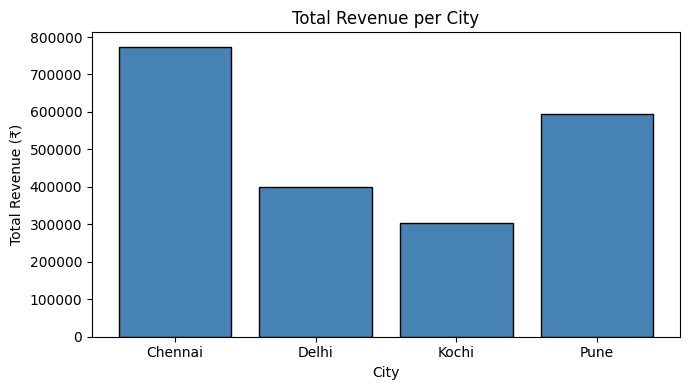

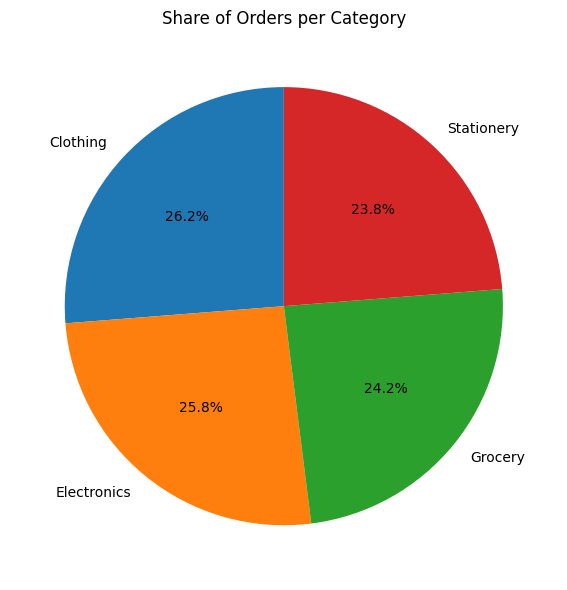

In [80]:
# (a) Bar chart of total revenue per city
city_rev = sales.groupby('city')['revenue'].sum()
plt.figure(figsize=(7, 4))
plt.bar(city_rev.index, city_rev.values, color='steelblue', edgecolor='black')
plt.title('Total Revenue per City')
plt.xlabel('City')
plt.ylabel('Total Revenue (₹)')
plt.tight_layout()
plt.show()

# (b) Pie chart of share of orders per category
cat_counts = sales['category'].value_counts()
plt.figure(figsize=(6, 6))
plt.pie(cat_counts.values, labels=cat_counts.index, autopct='%1.1f%%', startangle=90)
plt.title('Share of Orders per Category')
plt.tight_layout()
plt.show()

---

## Question 18  ·  *3 marks*
### Histogram and scatter plot

**(a)** Draw a **histogram** of `revenue` with 25 bins.
**(b)** Draw a **scatter plot** of `units` (x) against `revenue` (y).
**(c)** In a comment, explain why the scatter plot shows separate bands rather than one cloud.

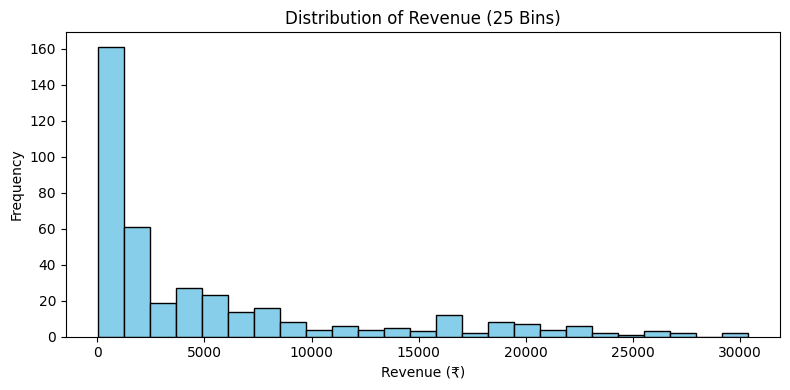

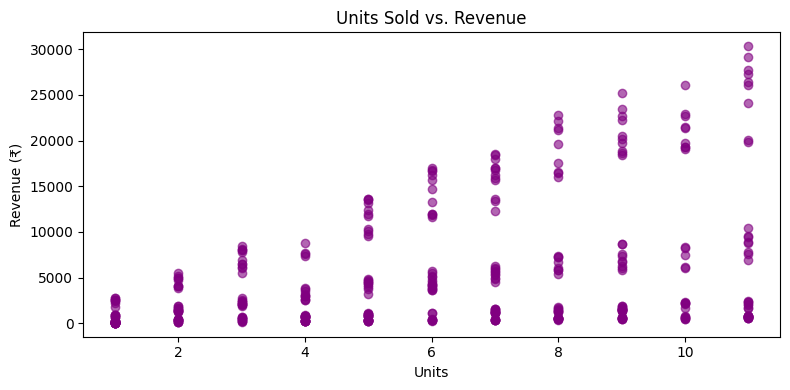

In [81]:
# (a) Histogram of revenue with 25 bins
plt.figure(figsize=(8, 4))
plt.hist(sales['revenue'], bins=25, color='skyblue', edgecolor='black')
plt.title('Distribution of Revenue (25 Bins)')
plt.xlabel('Revenue (₹)')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()

# (b) Scatter plot of units vs revenue
plt.figure(figsize=(8, 4))
plt.scatter(sales['units'], sales['revenue'], alpha=0.6, color='purple')
plt.title('Units Sold vs. Revenue')
plt.xlabel('Units')
plt.ylabel('Revenue (₹)')
plt.tight_layout()
plt.show()

# (c) Explanation:
# The scatter plot shows separate vertical bands because 'units' takes only discrete integer values (1 to 11),
# and distinct horizontal/sloped clusters appear due to the huge price gap between categories (e.g., Electronics ~₹2200 vs Stationery ~₹60).

---

## Question 19  ·  *3 marks*
### Line chart from a time series

Using the `monthly` DataFrame (`month`, `revenue_k`, `footfall`):

**(a)** Draw a **line chart** of `revenue_k` against `month`.
**(b)** Add markers to the line and a grid.
**(c)** In a comment, describe the two patterns you can see.

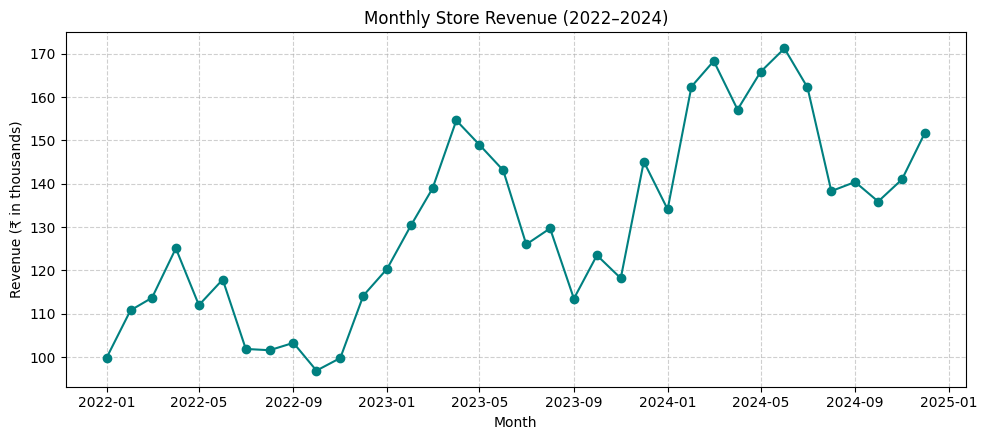

In [82]:
# (a & b) Line chart of revenue_k against month with markers and grid
plt.figure(figsize=(10, 4.5))
plt.plot(monthly['month'], monthly['revenue_k'], marker='o', linestyle='-', color='teal')
plt.title('Monthly Store Revenue (2022–2024)')
plt.xlabel('Month')
plt.ylabel('Revenue (₹ in thousands)')
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

# (c) Two patterns visible:
# 1. Upward Trend: Overall revenue steadily increases over the 36-month period (from ~100k to ~165k).
# 2. Seasonality: Regular cyclical peaks and troughs repeat every 12 months (annual seasonal pattern).

---

## Question 20  ·  *5 marks*
### Mini case study — one figure, four panels

Build a **2 × 2 grid of charts** with `fig, ax = plt.subplots(2, 2, figsize=(12, 8))`:

| Panel | Chart |
|---|---|
| top-left | bar chart of **total revenue per city** |
| top-right | histogram of `revenue` |
| bottom-left | line chart of `monthly['revenue_k']` over time |
| bottom-right | bar chart of **average revenue per seller** |

Give every panel a title, label the axes, and finish with `plt.tight_layout()`.

Then write **two findings** you can read off the figure, as a comment or a markdown cell.

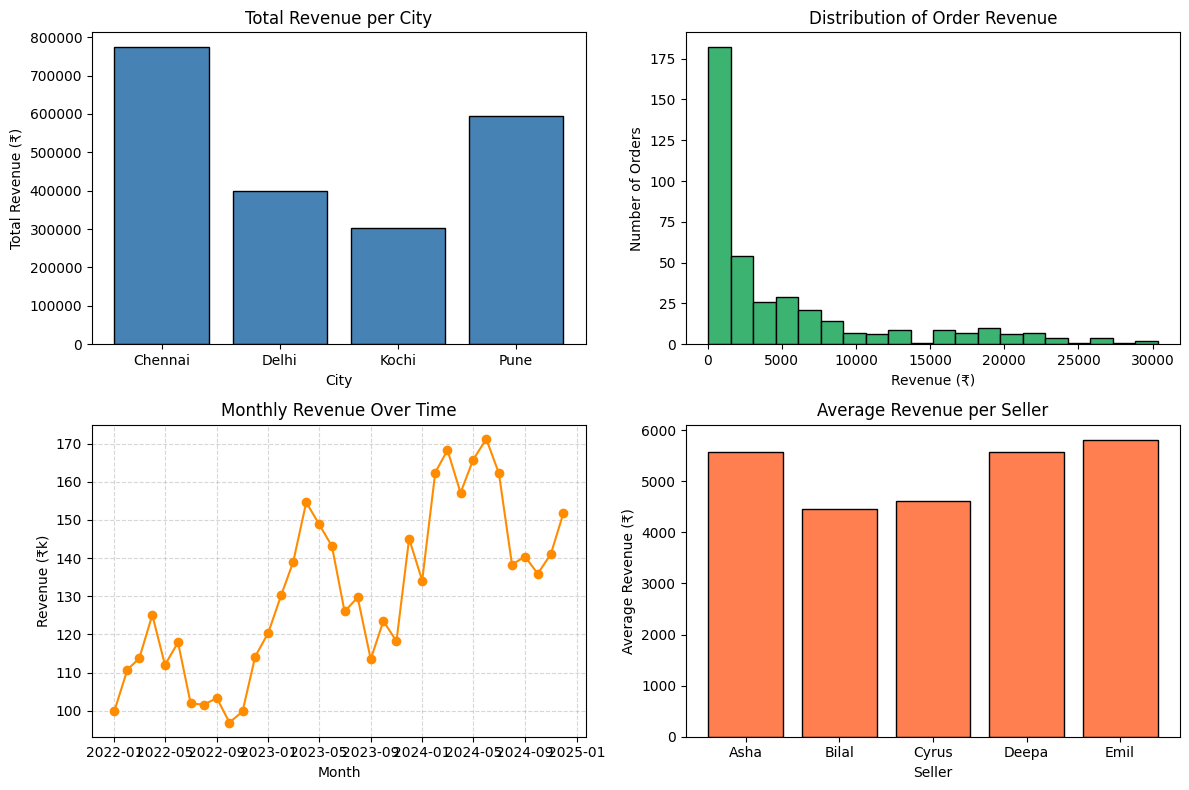

In [83]:
fig, ax = plt.subplots(2, 2, figsize=(12, 8))

# Top-left: bar chart of total revenue per city
city_rev = sales.groupby('city')['revenue'].sum()
ax[0, 0].bar(city_rev.index, city_rev.values, color='steelblue', edgecolor='black')
ax[0, 0].set_title('Total Revenue per City')
ax[0, 0].set_xlabel('City')
ax[0, 0].set_ylabel('Total Revenue (₹)')

# Top-right: histogram of revenue
ax[0, 1].hist(sales['revenue'], bins=20, color='mediumseagreen', edgecolor='black')
ax[0, 1].set_title('Distribution of Order Revenue')
ax[0, 1].set_xlabel('Revenue (₹)')
ax[0, 1].set_ylabel('Number of Orders')

# Bottom-left: line chart of monthly['revenue_k'] over time
ax[1, 0].plot(monthly['month'], monthly['revenue_k'], marker='o', color='darkorange')
ax[1, 0].set_title('Monthly Revenue Over Time')
ax[1, 0].set_xlabel('Month')
ax[1, 0].set_ylabel('Revenue (₹k)')
ax[1, 0].grid(True, linestyle='--', alpha=0.5)

# Bottom-right: bar chart of average revenue per seller
seller_avg = sales.groupby('seller')['revenue'].mean()
ax[1, 1].bar(seller_avg.index, seller_avg.values, color='coral', edgecolor='black')
ax[1, 1].set_title('Average Revenue per Seller')
ax[1, 1].set_xlabel('Seller')
ax[1, 1].set_ylabel('Average Revenue (₹)')

plt.tight_layout()
plt.show()

# Two findings:
# 1. Chennai generates the highest total revenue among all cities, while Kochi generates the lowest.
# 2. Order revenue is heavily right-skewed (most orders are under ₹5,000, with a few high-value Electronics orders pushing the tail up to ₹30,000).

---

## ✅ Before you submit

- [ ] Name and roll number filled in at the top
- [ ] The **setup cell** was run first, and every later cell has been run
- [ ] All outputs and charts are visible
- [ ] Every chart has a **title** and **axis labels**
- [ ] Saved as **`Pandas_Assignment_<YourName>_<RollNo>.ipynb`**

**All the best!** 🎯